# Tarea – Capítulo 4: Distribuciones especiales de probabilidad Juan Camilo Sanchez Garcia
**Serie Schaum – Probabilidad y Estadística (Spiegel, Schiller, Srinivasan)**

Ejercicios asignados con mi código de estudiante (obtenidos con `sort!(sample([61:94; 98:104; 108:120], 15, replace=false, ordered=false))`):

**4.65, 4.76, 4.77, 4.78, 4.79, 4.91, 4.92, 4.101, 4.103, 4.104, 4.109, 4.116, 4.117, 4.118 y 4.120**

Los enunciados están traducidos del libro. En cada ejercicio se presenta: enunciado, procedimiento analítico, verificación en Julia (paquete `Distributions`) y, cuando ayuda, una gráfica (paquete `Plots`).

**Notación:** $\Phi(z)$ es la función de distribución de la normal estándar; $\nu$ son los grados de libertad. Para las distribuciones $\chi^2$, $t$ y $F$ se usa la convención del libro: $\chi^2_p$, $t_p$, $F_{p,\nu_1,\nu_2}$ son los valores con área $p$ **a su izquierda**.

In [ ]:
using Random, Distributions, Statistics, Plots

# Cambia 1234 por tu código de estudiante y corre esta celda
Random.seed!(1234)

# Lista de ejercicios que salió con mi código
ejercicios = [65, 76, 77, 78, 79, 91, 92, 101, 103, 104, 109, 116, 117, 118, 120]

default(size = (650, 350))

# --- Funciones auxiliares para graficar densidades con áreas sombreadas ---
function curva(d; lo = quantile(d, 0.0005), hi = quantile(d, 0.9995), titulo = "")
    xs = range(lo, hi, length = 500)
    plot(xs, pdf.(d, xs), lw = 2, c = :black, title = titulo,
         xlabel = "x", ylabel = "f(x)", legend = false)
end

function sombra!(p, d, a, b; lo = quantile(d, 0.0005), hi = quantile(d, 0.9995), color = :orange)
    xs = range(max(a, lo), min(b, hi), length = 300)
    plot!(p, xs, pdf.(d, xs), fillrange = 0, fillalpha = 0.45, c = color, lw = 0)
    return p
end

sombra! (generic function with 1 method)

---
## Ejercicio 4.65
**Enunciado.** Hallar la probabilidad de obtener un total de 11 (a) una vez, (b) dos veces, en dos lanzamientos de un par de dados legales.

**Procedimiento.**

Con un par de dados, el total 11 sale solo con $(5,6)$ y $(6,5)$: 2 resultados favorables de 36. Entonces
$$p = P(\text{total }11) = \frac{2}{36} = \frac{1}{18}, \qquad q = 1-p = \frac{17}{18}.$$

Cada lanzamiento del par es un ensayo independiente con la misma probabilidad de éxito, así que $X$ = número de veces que sale 11 en $n=2$ lanzamientos tiene distribución binomial $X\sim \text{Bin}(2,\,1/18)$, con
$$P(X=x)=\binom{n}{x}p^x q^{n-x}.$$

**(a)** Una vez:
$$P(X=1)=\binom{2}{1}\left(\frac{1}{18}\right)\left(\frac{17}{18}\right)=\frac{34}{324}=\frac{17}{162}\approx 0.1049.$$

**(b)** Dos veces:
$$P(X=2)=\binom{2}{2}\left(\frac{1}{18}\right)^2=\frac{1}{324}\approx 0.00309.$$

(a) P(X=1) = 0.10493827160493824   exacto: 17//162
(b) P(X=2) = 0.0030864197530864183   exacto: 1//324


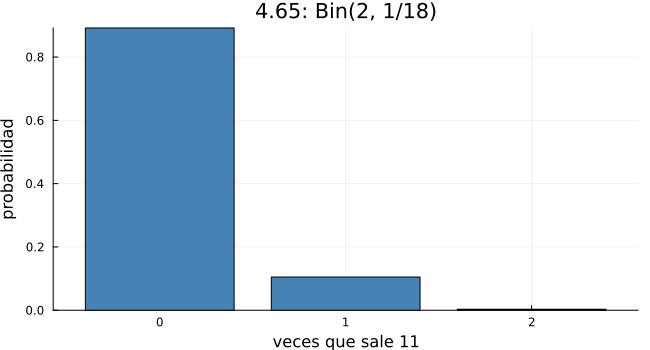

In [ ]:
X = Binomial(2, 1/18)
println("(a) P(X=1) = ", pdf(X, 1), "   exacto: ", 2 * (1//18) * (17//18))
println("(b) P(X=2) = ", pdf(X, 2), "   exacto: ", (1//18)^2)

bar(0:2, pdf.(X, 0:2), xticks = 0:2, xlabel = "veces que sale 11", ylabel = "probabilidad",
    title = "4.65: Bin(2, 1/18)", legend = false, c = :steelblue)

---
## Ejercicio 4.70
**Enunciado.** Demostrar que si una distribución binomial con $n=100$ es simétrica, su coeficiente de curtosis es 2.9.

**Procedimiento.**

*Paso 1: la simetría implica $p=q=1/2$.* El coeficiente de asimetría de la binomial es
$$\alpha_3=\frac{q-p}{\sqrt{npq}}.$$
La distribución es simétrica si y solo si $\alpha_3=0$, es decir, $q=p$. Como $p+q=1$, resulta $p=q=\tfrac12$.

*Paso 2: coeficiente de curtosis de la binomial.*
$$\alpha_4=\frac{\mu_4}{\sigma^4}=3+\frac{1-6pq}{npq}.$$

*Paso 3: sustituir* $n=100$, $p=q=\tfrac12$, de modo que $pq=\tfrac14$ y $npq=25$:
$$\alpha_4 = 3+\frac{1-6\cdot\frac14}{25}=3+\frac{1-1.5}{25}=3-0.02=2.98.$$

**Observación:** el valor exacto es $2.98$, que es ligeramente menor que 3 (distribución algo más "achatada" que la normal) y que el enunciado reporta como $2.9$ al truncar a un decimal. Redondeado a un decimal sería $3.0$. Por eso se muestra el valor exacto $2.98$ y se comprueba directamente desde la definición.

α3 = -0.0
α4 (definición) = 2.98
α4 (fórmula)    = 2.98


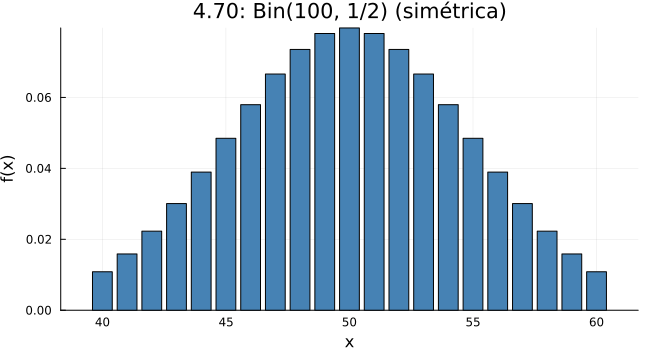

In [ ]:
n, p = 100, 0.5
q = 1 - p
d = Binomial(n, p)
μ  = mean(d)
σ² = var(d)

asimetria = sum((x - μ)^3 * pdf(d, x) for x in 0:n) / σ²^(3/2)   # α3
curtosis  = sum((x - μ)^4 * pdf(d, x) for x in 0:n) / σ²^2        # α4 desde la definición
formula   = 3 + (1 - 6p*q) / (n*p*q)                              # α4 = 3 + (1-6pq)/(npq)

println("α3 = ", round(asimetria, digits = 6))
println("α4 (definición) = ", round(curtosis, digits = 6))
println("α4 (fórmula)    = ", formula)

bar(40:60, pdf.(d, 40:60), xlabel = "x", ylabel = "f(x)",
    title = "4.70: Bin(100, 1/2) (simétrica)", legend = false, c = :steelblue)

---
## Ejercicio 4.71
**Enunciado.** Evaluar (a) $\sum (x-\mu)^3 f(x)$, (b) $\sum (x-\mu)^4 f(x)$ para la distribución binomial.

**Procedimiento.**

Estas sumas son el tercer y el cuarto momento centrales, $\mu_3$ y $\mu_4$. Una variable binomial es la suma $X=B_1+\dots+B_n$ de $n$ ensayos de Bernoulli independientes, con $\mu=np$. Sea $Y_i=B_i-p$, de modo que $X-\mu=\sum Y_i$. Cada $Y_i$ vale $q$ con probabilidad $p$ y $-p$ con probabilidad $q$, y $E[Y_i]=0$.

Momentos de un solo $Y$ (usando $p+q=1$ y $p^3+q^3=1-3pq$):
$$E[Y^2]=pq^2+qp^2=pq,$$
$$E[Y^3]=pq^3-qp^3=pq(q^2-p^2)=pq(q-p),$$
$$E[Y^4]=pq^4+qp^4=pq(q^3+p^3)=pq(1-3pq).$$

**(a)** Al desarrollar $\left(\sum Y_i\right)^3$, todo término donde aparece algún $Y_i$ con exponente 1 tiene esperanza cero (independencia y $E[Y_i]=0$). Solo sobreviven los términos $Y_i^3$:
$$\mu_3=\sum_i E[Y_i^3]=n\,pq(q-p)=\boxed{npq(q-p)}.$$

**(b)** En $\left(\sum Y_i\right)^4$ sobreviven los términos $Y_i^4$ y los de la forma $Y_i^2Y_j^2$ con $i\ne j$. Cada par $\{i,j\}$ aparece $\binom{4}{2}=6$ veces y hay $\binom{n}{2}$ pares, o sea $3n(n-1)$ términos de ese tipo:
$$\mu_4=n\,E[Y^4]+3n(n-1)\big(E[Y^2]\big)^2 = npq(1-3pq)+3n(n-1)p^2q^2.$$
Desarrollando:
$$\mu_4 = npq-3np^2q^2+3n^2p^2q^2-3np^2q^2 = \boxed{npq(1-6pq)+3n^2p^2q^2}.$$

(Con $\mu_2=npq$ esto da $\alpha_3=\frac{q-p}{\sqrt{npq}}$ y $\alpha_4=3+\frac{1-6pq}{npq}$, las fórmulas usadas en el ejercicio 4.70.)

In [ ]:
# Verificación numérica con n = 12, p = 0.3 (cualquier valor sirve)
n, p = 12, 0.3
q = 1 - p
d = Binomial(n, p)
μ = n * p

m3 = sum((x - μ)^3 * pdf(d, x) for x in 0:n)
m4 = sum((x - μ)^4 * pdf(d, x) for x in 0:n)

println("(a) suma = ", m3, "   fórmula npq(q-p) = ", n*p*q*(q - p))
println("(b) suma = ", m4, "   fórmula npq(1-6pq)+3n²p²q² = ", n*p*q*(1 - 6p*q) + 3n^2*p^2*q^2)
println("¿coinciden? ", isapprox(m3, n*p*q*(q - p)), " y ", isapprox(m4, n*p*q*(1 - 6p*q) + 3n^2*p^2*q^2))

(a) suma = 1.0079999999999945   fórmula npq(q-p) = 1.0079999999999998
(b) suma = 18.395999999999987   fórmula npq(1-6pq)+3n²p²q² = 18.395999999999994
¿coinciden? true y true


---
## Ejercicio 4.76
**Enunciado.** Si $Z$ tiene distribución normal con media 0 y varianza 1, hallar: (a) $P(Z\ge -1.64)$, (b) $P(-1.96\le Z\le 1.96)$, (c) $P(|Z|\ge 1)$.

**Procedimiento.** Se usa $\Phi(z)=P(Z\le z)$ y la simetría $\Phi(-z)=1-\Phi(z)$.

**(a)**
$$P(Z\ge -1.64)=1-\Phi(-1.64)=\Phi(1.64)=0.9495.$$

**(b)**
$$P(-1.96\le Z\le 1.96)=\Phi(1.96)-\Phi(-1.96)=2\Phi(1.96)-1=2(0.9750)-1=0.9500.$$

**(c)** $|Z|\ge 1$ equivale a $Z\le -1$ o $Z\ge 1$; por simetría
$$P(|Z|\ge 1)=2\,[1-\Phi(1)]=2(1-0.8413)=0.3173.$$

**Nota:** la respuesta que el libro da para el inciso (c) es 0.6826, que corresponde a $P(|Z|\le 1)=2\Phi(1)-1$ (el complemento). Con el enunciado tal como está impreso ($\ge$), el resultado correcto es $0.3173$; abajo se calculan ambos.

(a) 0.9495
(b) 0.95
(c) P(|Z|≥1) = 0.3173   |   P(|Z|≤1) = 0.6827


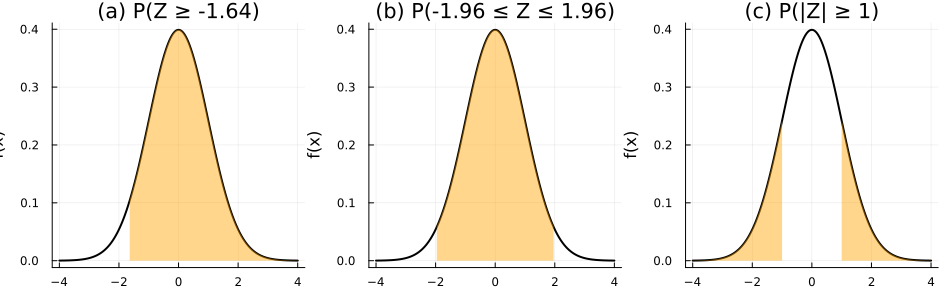

In [ ]:
Z = Normal(0, 1)

a = ccdf(Z, -1.64)                 # P(Z ≥ -1.64)
b = cdf(Z, 1.96) - cdf(Z, -1.96)   # P(-1.96 ≤ Z ≤ 1.96)
c = 2 * ccdf(Z, 1)                 # P(|Z| ≥ 1)
c_comp = cdf(Z, 1) - cdf(Z, -1)    # P(|Z| ≤ 1)  (lo que da el libro como respuesta)

println("(a) ", round(a, digits = 4))
println("(b) ", round(b, digits = 4))
println("(c) P(|Z|≥1) = ", round(c, digits = 4), "   |   P(|Z|≤1) = ", round(c_comp, digits = 4))

pa = sombra!(curva(Z, lo = -4, hi = 4, titulo = "(a) P(Z ≥ -1.64)"), Z, -1.64, 4, lo = -4, hi = 4)
pb = sombra!(curva(Z, lo = -4, hi = 4, titulo = "(b) P(-1.96 ≤ Z ≤ 1.96)"), Z, -1.96, 1.96, lo = -4, hi = 4)
pc = curva(Z, lo = -4, hi = 4, titulo = "(c) P(|Z| ≥ 1)")
sombra!(pc, Z, -4, -1, lo = -4, hi = 4); sombra!(pc, Z, 1, 4, lo = -4, hi = 4)
plot(pa, pb, pc, layout = (1, 3), size = (950, 300))

---
## Ejercicio 4.77
**Enunciado.** Hallar los valores de $z$ tales que: (a) el área a la derecha de $z$ es 0.2266; (b) el área a la izquierda de $z$ es 0.0314; (c) el área entre $-0.23$ y $z$ es 0.5722; (d) el área entre 1.15 y $z$ es 0.0730; (e) el área entre $-z$ y $z$ es 0.9000.

**Procedimiento.** Se plantea cada condición como una ecuación para $\Phi(z)$ y se invierte con la tabla (o con $\Phi^{-1}$).

**(a)** $1-\Phi(z)=0.2266\Rightarrow \Phi(z)=0.7734\Rightarrow z\approx \mathbf{0.75}$.

**(b)** $\Phi(z)=0.0314\Rightarrow z\approx \mathbf{-1.86}$.

**(c)** $\Phi(z)-\Phi(-0.23)=0.5722$ con $\Phi(-0.23)=0.4090$, entonces $\Phi(z)=0.9812\Rightarrow z\approx\mathbf{2.08}$. (Debe ser $z>-0.23$, porque a la izquierda de $-0.23$ el área total es solo $0.4090<0.5722$.)

**(d)** Con $\Phi(1.15)=0.8749$ hay dos posibilidades, según $z$ esté a la derecha o a la izquierda de 1.15:
- $z>1.15$: $\Phi(z)=0.8749+0.0730=0.9479\Rightarrow z\approx\mathbf{1.625}$.
- $z<1.15$: $\Phi(z)=0.8749-0.0730=0.8019\Rightarrow z\approx\mathbf{0.849}$.

**(e)** $\Phi(z)-\Phi(-z)=2\Phi(z)-1=0.9000\Rightarrow\Phi(z)=0.9500\Rightarrow z\approx\mathbf{\pm 1.645}$.

(a) z = 0.75
(b) z = -1.861
(c) z = 2.08
(d) z = 1.625  o  z = 0.849
(e) z = ±1.645


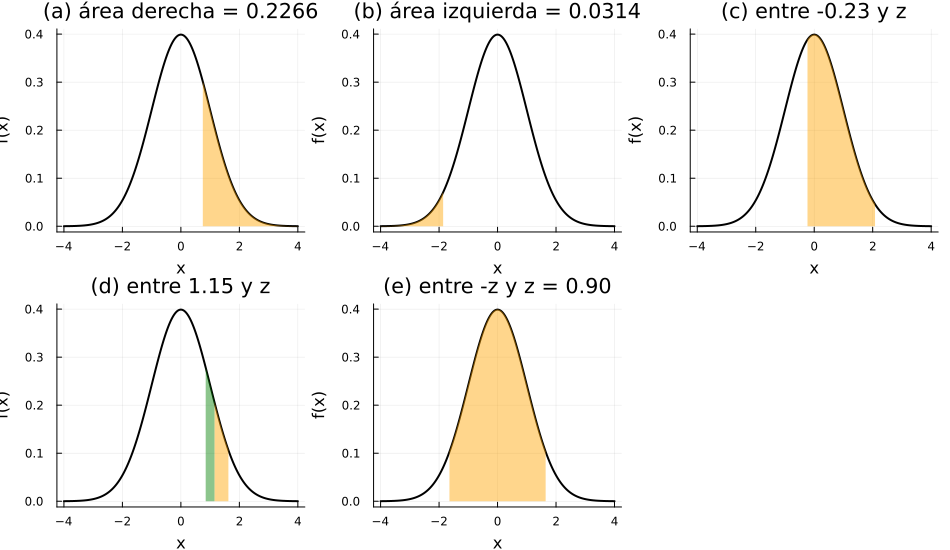

In [ ]:
Z = Normal()

za  = quantile(Z, 1 - 0.2266)
zb  = quantile(Z, 0.0314)
zc  = quantile(Z, 0.5722 + cdf(Z, -0.23))
zd1 = quantile(Z, cdf(Z, 1.15) + 0.0730)
zd2 = quantile(Z, cdf(Z, 1.15) - 0.0730)
ze  = quantile(Z, 0.95)

println("(a) z = ", round(za, digits = 3))
println("(b) z = ", round(zb, digits = 3))
println("(c) z = ", round(zc, digits = 3))
println("(d) z = ", round(zd1, digits = 3), "  o  z = ", round(zd2, digits = 3))
println("(e) z = ±", round(ze, digits = 3))

kw = (lo = -4, hi = 4)
pa = sombra!(curva(Z; kw..., titulo = "(a) área derecha = 0.2266"), Z, za, 4; kw...)
pb = sombra!(curva(Z; kw..., titulo = "(b) área izquierda = 0.0314"), Z, -4, zb; kw...)
pc = sombra!(curva(Z; kw..., titulo = "(c) entre -0.23 y z"), Z, -0.23, zc; kw...)
pd = curva(Z; kw..., titulo = "(d) entre 1.15 y z")
sombra!(pd, Z, 1.15, zd1; kw...); sombra!(pd, Z, zd2, 1.15; kw..., color = :green)
pe = sombra!(curva(Z; kw..., titulo = "(e) entre -z y z = 0.90"), Z, -ze, ze; kw...)
plot(pa, pb, pc, pd, pe, plot(framestyle = :none), layout = (2, 3), size = (950, 550))

---
## Ejercicio 4.78
**Enunciado.** Hallar $z_1$ si $P(Z\ge z_1)=0.84$, donde $Z$ es normal con media 0 y varianza 1.

**Procedimiento.** Como $P(Z\ge z_1)=0.84$ es mayor que $0.5$, $z_1$ debe quedar a la izquierda de la media (será negativo). El área a la izquierda es
$$P(Z< z_1)=1-0.84=0.16\;\Rightarrow\;\Phi(z_1)=0.16.$$
Por simetría, $\Phi(z_1)=0.16$ equivale a $\Phi(-z_1)=0.84$, y en la tabla $\Phi(0.99)=0.8389$, $\Phi(1.00)=0.8413$, así que $-z_1\approx0.995$:
$$z_1\approx\mathbf{-0.995}.$$
(El valor exacto con la función inversa es $-0.9945$.)

z₁ = -0.9945   verificación P(Z ≥ z₁) = 0.84


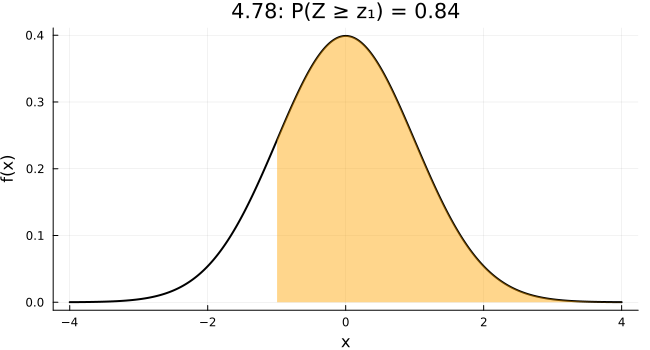

In [ ]:
Z = Normal()
z1 = quantile(Z, 1 - 0.84)
println("z₁ = ", round(z1, digits = 4), "   verificación P(Z ≥ z₁) = ", round(ccdf(Z, z1), digits = 4))

sombra!(curva(Z, lo = -4, hi = 4, titulo = "4.78: P(Z ≥ z₁) = 0.84"), Z, z1, 4, lo = -4, hi = 4)

---
## Ejercicio 4.79
**Enunciado.** Si $X$ tiene distribución normal con media 5 y desviación estándar 2, hallar $P(X>8)$.

**Procedimiento.** Se estandariza con $Z=\dfrac{X-\mu}{\sigma}$:
$$P(X>8)=P\!\left(Z>\frac{8-5}{2}\right)=P(Z>1.5)=1-\Phi(1.5)=1-0.9332=\mathbf{0.0668}.$$

P(X>8) directo      = 0.0668
P(Z>1.5) estándar   = 0.0668


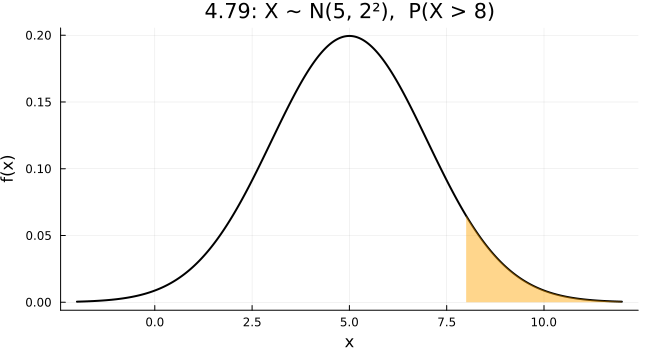

In [ ]:
X = Normal(5, 2)
println("P(X>8) directo      = ", round(ccdf(X, 8), digits = 4))
println("P(Z>1.5) estándar   = ", round(ccdf(Normal(), (8 - 5)/2), digits = 4))

sombra!(curva(X, lo = -2, hi = 12, titulo = "4.79: X ~ N(5, 2²),  P(X > 8)"), X, 8, 12, lo = -2, hi = 12)

---
## Ejercicio 4.91
**Enunciado.** En el Problema 4.90 (3 % de los focos fabricados son defectuosos; muestra de 100 focos), hallar la probabilidad de que (a) más de 5, (b) entre 1 y 3, (c) menos o igual que 2, focos sean defectuosos.

**Procedimiento.** Como $n=100$ es grande y $p=0.03$ es pequeño, el número de defectuosos $X$ se aproxima por una Poisson (así se resolvió el 4.90) con
$$\lambda=np=100(0.03)=3,\qquad P(X=x)=\frac{e^{-3}3^x}{x!}.$$
Valores del 4.90: $P(0)=0.04979$, $P(1)=0.1494$, $P(2)=0.2241$, $P(3)=0.2241$, $P(4)=0.1680$, $P(5)=0.1008$.

**(a)** $P(X>5)=1-P(X\le5)=1-(0.04979+0.1494+0.2241+0.2241+0.1680+0.1008)=1-0.9162\approx\mathbf{0.0838}$.

**(b)** Tomando "entre 1 y 3" de forma inclusiva: $P(1\le X\le3)=0.1494+0.2241+0.2241=\mathbf{0.5976}$.

**(c)** $P(X\le2)=0.04979+0.1494+0.2241=\mathbf{0.4232}$.

(Los valores calculados sin redondear dan $0.0839$, $0.5974$ y $0.4232$; la pequeña diferencia con el libro viene de sumar probabilidades ya redondeadas.)

Poisson(3):  (a) 0.0839  (b) 0.5974  (c) 0.4232
Bin(100,.03): (a) 0.0808  (b) 0.5997  (c) 0.4198


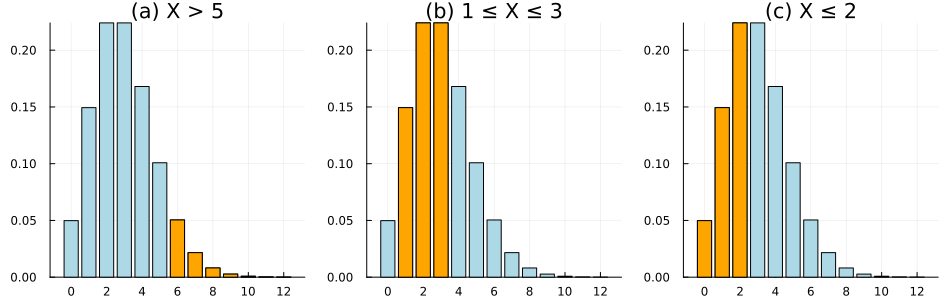

In [ ]:
λ = 100 * 0.03
P = Poisson(λ)

a = ccdf(P, 5)                # P(X > 5)
b = cdf(P, 3) - cdf(P, 0)     # P(1 ≤ X ≤ 3)
c = cdf(P, 2)                 # P(X ≤ 2)
println("Poisson(3):  (a) ", round(a, digits = 4), "  (b) ", round(b, digits = 4), "  (c) ", round(c, digits = 4))

# Comparación con la binomial exacta Bin(100, 0.03)
B = Binomial(100, 0.03)
println("Bin(100,.03): (a) ", round(ccdf(B, 5), digits = 4),
        "  (b) ", round(cdf(B, 3) - cdf(B, 0), digits = 4),
        "  (c) ", round(cdf(B, 2), digits = 4))

xs = 0:12
p1 = bar(xs, pdf.(P, xs), c = :lightblue, legend = false, title = "(a) X > 5");   bar!(p1, 6:12, pdf.(P, 6:12), c = :orange)
p2 = bar(xs, pdf.(P, xs), c = :lightblue, legend = false, title = "(b) 1 ≤ X ≤ 3"); bar!(p2, 1:3, pdf.(P, 1:3), c = :orange)
p3 = bar(xs, pdf.(P, xs), c = :lightblue, legend = false, title = "(c) X ≤ 2");     bar!(p3, 0:2, pdf.(P, 0:2), c = :orange)
plot(p1, p2, p3, layout = (1, 3), size = (950, 300))

---
## Ejercicio 4.92
**Enunciado.** Una bolsa contiene 1 bola roja y 7 blancas. Se saca una bola, se observa su color y se devuelve a la bolsa, mezclando bien. Usando (a) la distribución binomial, (b) la aproximación de Poisson a la binomial, hallar la probabilidad de que en 8 extracciones así se obtenga una bola roja exactamente 3 veces.

**Procedimiento.** Con reemplazo, las extracciones son independientes y $p=P(\text{roja})=\tfrac18$, $q=\tfrac78$, $n=8$.

**(a) Binomial.**
$$P(X=3)=\binom{8}{3}\left(\frac18\right)^3\left(\frac78\right)^5=56\cdot\frac{7^5}{8^8}=\frac{117649}{2097152}\approx\mathbf{0.05610}.$$

**(b) Poisson.** Con $\lambda=np=8\cdot\frac18=1$:
$$P(X=3)=\frac{e^{-\lambda}\lambda^3}{3!}=\frac{e^{-1}}{6}\approx\mathbf{0.06131}.$$

La aproximación no es muy buena porque $p=1/8$ no es pequeño y $n=8$ no es grande.

(a) Binomial: 0.0561   exacto = 117649//2097152
(b) Poisson : 0.06131


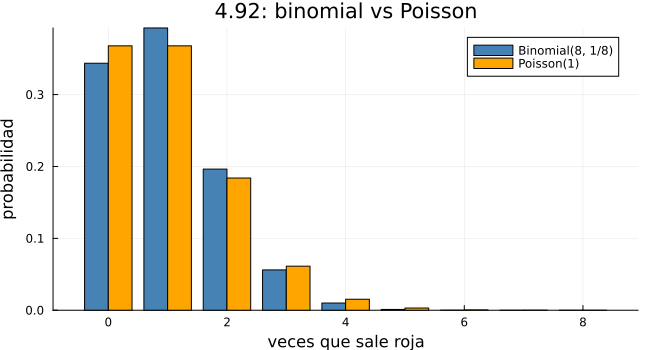

In [ ]:
a = pdf(Binomial(8, 1/8), 3)
b = pdf(Poisson(8 * (1/8)), 3)
println("(a) Binomial: ", round(a, digits = 5), "   exacto = ", binomial(8, 3) * 7^5 // 8^8)
println("(b) Poisson : ", round(b, digits = 5))

xs = 0:8
bar(xs .- 0.2, pdf.(Binomial(8, 1/8), xs), bar_width = 0.4, label = "Binomial(8, 1/8)", c = :steelblue,
    xlabel = "veces que sale roja", ylabel = "probabilidad", title = "4.92: binomial vs Poisson")
bar!(xs .+ 0.2, pdf.(Poisson(1), xs), bar_width = 0.4, label = "Poisson(1)", c = :orange)

---
## Ejercicio 4.101
**Enunciado.** Sea $X$ uniformemente distribuida en $-2\le x\le 2$. Hallar (a) $P(X<1)$, (b) $P\!\left(|X-1|\ge\tfrac12\right)$.

**Procedimiento.** La densidad es $f(x)=\dfrac{1}{b-a}=\dfrac14$ para $-2\le x\le2$.

**(a)**
$$P(X<1)=\int_{-2}^{1}\frac14\,dx=\frac{1-(-2)}{4}=\frac34.$$

**(b)** $|X-1|\ge\frac12$ equivale a $X\le\frac12$ o $X\ge\frac32$. Son intervalos disjuntos, así que se suman:
$$P\!\left(|X-1|\ge\tfrac12\right)=\int_{-2}^{1/2}\frac14\,dx+\int_{3/2}^{2}\frac14\,dx=\frac{2.5}{4}+\frac{0.5}{4}=\frac34.$$
(Equivalentemente, $1-P\!\left(\tfrac12<X<\tfrac32\right)=1-\tfrac14=\tfrac34$.)

(a) P(X<1) = 0.75
(b) P(|X-1| ≥ 1/2) = 0.75


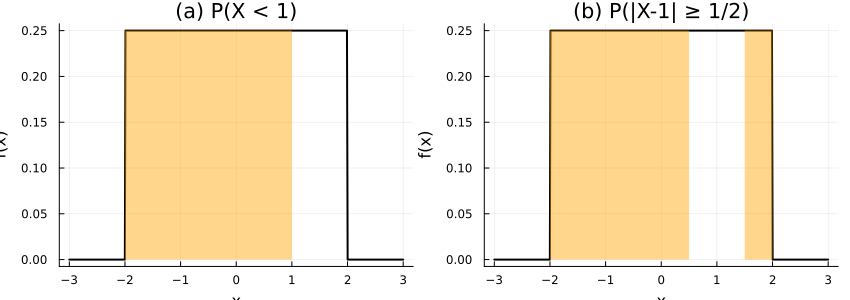

In [ ]:
U = Uniform(-2, 2)
a = cdf(U, 1)
b = cdf(U, 1/2) + ccdf(U, 3/2)
println("(a) P(X<1) = ", a)
println("(b) P(|X-1| ≥ 1/2) = ", b)

kw = (lo = -3, hi = 3)
pa = sombra!(curva(U; kw..., titulo = "(a) P(X < 1)"), U, -2, 1; kw...)
pb = curva(U; kw..., titulo = "(b) P(|X-1| ≥ 1/2)")
sombra!(pb, U, -2, 0.5; kw...); sombra!(pb, U, 1.5, 2; kw...)
plot(pa, pb, layout = (1, 2), size = (850, 300))

---
## Ejercicio 4.103
**Enunciado.** Determinar el coeficiente de (a) asimetría, (b) curtosis de una distribución uniforme.

**Procedimiento.** Sea $X\sim U(a,b)$ con $f(x)=\frac{1}{b-a}$. Se centra la variable: $Y=X-\frac{a+b}{2}$ es uniforme en $[-h,h]$ con $h=\frac{b-a}{2}$ y $f(y)=\frac1{2h}$. Los momentos centrales de $X$ son los momentos de $Y$:
$$\mu_k=\int_{-h}^{h}y^k\,\frac{1}{2h}\,dy=\frac{1}{2h}\cdot\frac{h^{k+1}-(-h)^{k+1}}{k+1}.$$

- $\mu_2=\dfrac{h^2}{3}=\dfrac{(b-a)^2}{12}=\sigma^2$.
- $\mu_3=0$ (integrando impar sobre intervalo simétrico).
- $\mu_4=\dfrac{h^4}{5}=\dfrac{(b-a)^4}{80}$ (resultado del ejercicio 4.102b).

**(a) Asimetría:**
$$\alpha_3=\frac{\mu_3}{\sigma^3}=\boxed{0}$$
La distribución es simétrica.

**(b) Curtosis:**
$$\alpha_4=\frac{\mu_4}{\sigma^4}=\frac{(b-a)^4/80}{\big[(b-a)^2/12\big]^2}=\frac{144}{80}=\boxed{\frac95=1.8}$$
Es menor que 3 (la normal), o sea más achatada, con exceso de curtosis $-1.2$.

In [ ]:
# Verificación numérica con integración de punto medio para a=2, b=7 (el resultado no depende de a y b)
a, b = 2.0, 7.0
N = 10^6
Δ = (b - a) / N
xs = [a + (i - 0.5) * Δ for i in 1:N]
f = 1 / (b - a)

μ  = sum(xs) * Δ * f
μ2 = sum((xs .- μ).^2) * Δ * f
μ3 = sum((xs .- μ).^3) * Δ * f
μ4 = sum((xs .- μ).^4) * Δ * f

println("α3 = ", round(μ3 / μ2^(3/2), digits = 5))
println("α4 = ", round(μ4 / μ2^2, digits = 5), "   (9/5 = ", 9/5, ")")

α3 = -0.0
α4 = 1.8   (9/5 = 1.8)


---
## Ejercicio 4.104
**Enunciado.** Si $X$ e $Y$ son independientes y ambas uniformemente distribuidas en el intervalo de 0 a 1, hallar $P\!\left(|X-Y|\ge\tfrac12\right)$.

**Procedimiento.** Por independencia, el punto $(X,Y)$ es uniforme en el cuadrado unitario $[0,1]^2$ (densidad conjunta 1), así que la probabilidad de un evento es el **área** de la región correspondiente.

$|X-Y|\ge\frac12$ se divide en dos regiones disjuntas:
- $X-Y\ge\frac12$: triángulo con vértices $(\frac12,0),(1,0),(1,\frac12)$, de área $\frac12\cdot\frac12\cdot\frac12=\frac18$.
- $Y-X\ge\frac12$: triángulo con vértices $(0,\frac12),(0,1),(\frac12,1)$, también de área $\frac18$.

$$P\!\left(|X-Y|\ge\tfrac12\right)=\frac18+\frac18=\boxed{\frac14}.$$

Como comprobación, $P(|X-Y|<\frac12)=1-\frac14=\frac34$: la banda central tiene área $1-2\left(\frac12\right)^2=\frac34$.

Simulación: 0.250375   exacto: 0.25


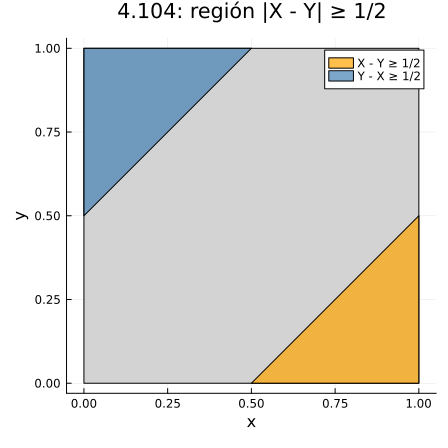

In [ ]:
# Verificación por simulación (Monte Carlo)
N = 10^6
x, y = rand(N), rand(N)
println("Simulación: ", mean(abs.(x .- y) .>= 0.5), "   exacto: 0.25")

# Región en el cuadrado unitario
p = plot(Shape([0, 1, 1, 0], [0, 0, 1, 1]), c = :lightgray, lc = :black, label = "",
         aspect_ratio = 1, xlabel = "x", ylabel = "y", title = "4.104: región |X - Y| ≥ 1/2", size = (450, 450))
plot!(p, Shape([0.5, 1, 1], [0, 0, 0.5]), c = :orange, fillalpha = 0.7, label = "X - Y ≥ 1/2")
plot!(p, Shape([0, 0, 0.5], [0.5, 1, 1]), c = :steelblue, fillalpha = 0.7, label = "Y - X ≥ 1/2")

---
## Ejercicio 4.109
**Enunciado.** Para una distribución chi cuadrado con 12 grados de libertad, hallar el valor de $\chi_c^2$ tal que (a) el área a la derecha de $\chi_c^2$ es 0.05, (b) el área a la izquierda de $\chi_c^2$ es 0.99, (c) el área a la derecha de $\chi_c^2$ es 0.025.

**Procedimiento.** Se busca el percentil correspondiente en la tabla de $\chi^2$ con $\nu=12$ (columna del área a la izquierda $p$, es decir $\chi^2_p$):

**(a)** Área derecha $0.05\Rightarrow$ área izquierda $0.95$: $\chi^2_{0.95}=\mathbf{21.0}$.

**(b)** Área izquierda $0.99$: $\chi^2_{0.99}=\mathbf{26.2}$.

**(c)** Área derecha $0.025\Rightarrow$ área izquierda $0.975$: $\chi^2_{0.975}=\mathbf{23.3}$.

(a) 21.03
(b) 26.22
(c) 23.34


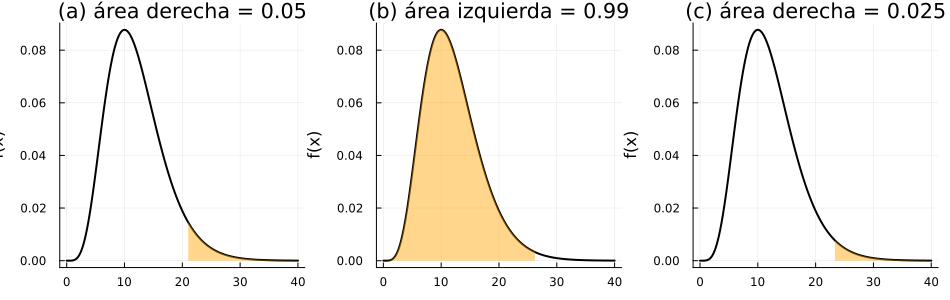

In [ ]:
X2 = Chisq(12)
a = quantile(X2, 0.95)
b = quantile(X2, 0.99)
c = quantile(X2, 0.975)
println("(a) ", round(a, digits = 2))
println("(b) ", round(b, digits = 2))
println("(c) ", round(c, digits = 2))

kw = (lo = 0.0, hi = 40.0)
pa = sombra!(curva(X2; kw..., titulo = "(a) área derecha = 0.05"), X2, a, 40; kw...)
pb = sombra!(curva(X2; kw..., titulo = "(b) área izquierda = 0.99"), X2, 0, b; kw...)
pc = sombra!(curva(X2; kw..., titulo = "(c) área derecha = 0.025"), X2, c, 40; kw...)
plot(pa, pb, pc, layout = (1, 3), size = (950, 300))

---
## Ejercicio 4.116
**Enunciado.** Para una distribución t de Student con 15 grados de libertad, hallar el valor de $t_1$ tal que (a) el área a la derecha de $t_1$ es 0.01, (b) el área a la izquierda de $t_1$ es 0.95, (c) el área a la derecha de $t_1$ es 0.10, (d) el área combinada a la derecha de $t_1$ y a la izquierda de $-t_1$ es 0.01, (e) el área entre $-t_1$ y $t_1$ es 0.95.

**Procedimiento.** La distribución t es simétrica, y se usa la tabla con $\nu=15$ (percentil $t_p$ = área izquierda $p$).

**(a)** Derecha $0.01\Rightarrow$ izquierda $0.99$: $t_{0.99}=\mathbf{2.60}$.

**(b)** Izquierda $0.95$: $t_{0.95}=\mathbf{1.75}$.

**(c)** Derecha $0.10\Rightarrow$ izquierda $0.90$: $t_{0.90}=\mathbf{1.34}$.

**(d)** Área combinada de las dos colas $=0.01$; por simetría cada cola tiene $0.005$, luego izquierda $=0.995$: $t_{0.995}=\mathbf{2.95}$.

**(e)** Área central $0.95\Rightarrow$ cada cola $0.025\Rightarrow$ izquierda $0.975$: $t_{0.975}=\mathbf{2.13}$.

(a) t₁ = 2.602
(b) t₁ = 1.753
(c) t₁ = 1.341
(d) t₁ = 2.947
(e) t₁ = 2.131


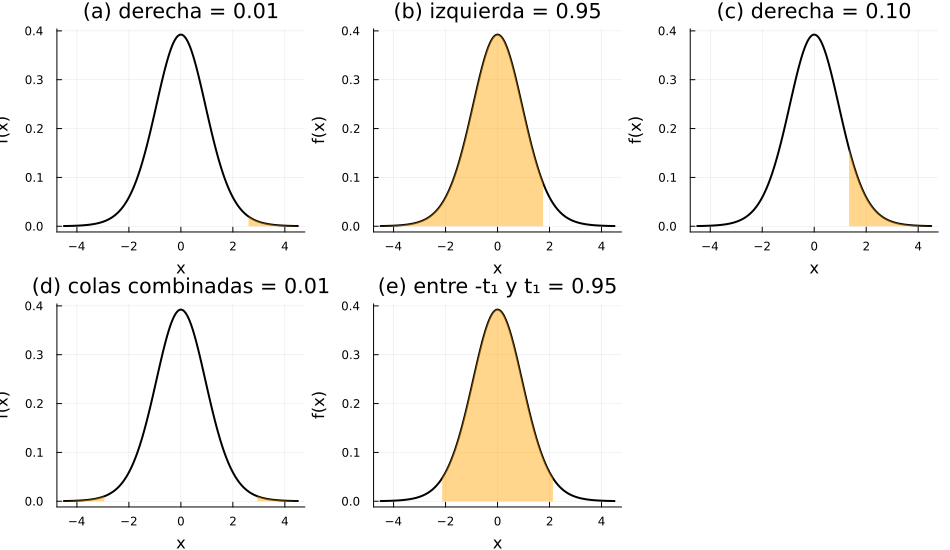

In [ ]:
T = TDist(15)
t_a = quantile(T, 0.99)
t_b = quantile(T, 0.95)
t_c = quantile(T, 0.90)
t_d = quantile(T, 0.995)
t_e = quantile(T, 0.975)
for (i, v) in zip("abcde", [t_a, t_b, t_c, t_d, t_e])
    println("($i) t₁ = ", round(v, digits = 3))
end

kw = (lo = -4.5, hi = 4.5)
pa = sombra!(curva(T; kw..., titulo = "(a) derecha = 0.01"), T, t_a, 5; kw...)
pb = sombra!(curva(T; kw..., titulo = "(b) izquierda = 0.95"), T, -5, t_b; kw...)
pc = sombra!(curva(T; kw..., titulo = "(c) derecha = 0.10"), T, t_c, 5; kw...)
pd = curva(T; kw..., titulo = "(d) colas combinadas = 0.01")
sombra!(pd, T, t_d, 5; kw...); sombra!(pd, T, -5, -t_d; kw...)
pe = sombra!(curva(T; kw..., titulo = "(e) entre -t₁ y t₁ = 0.95"), T, -t_e, t_e; kw...)
plot(pa, pb, pc, pd, pe, plot(framestyle = :none), layout = (2, 3), size = (950, 550))

---
## Ejercicio 4.117
**Enunciado.** Hallar los valores de $t$ para los cuales el área de la cola derecha de la distribución t es 0.01, si los grados de libertad $\nu$ son (a) 4, (b) 12, (c) 25, (d) 60, (e) 150.

**Procedimiento.** Área derecha $0.01\Rightarrow$ área izquierda $0.99$, así que se busca $t_{0.99}$ para cada $\nu$:

| $\nu$ | 4 | 12 | 25 | 60 | 150 |
|---|---|---|---|---|---|
| $t_{0.99}$ | 3.75 | 2.68 | 2.48 | 2.39 | 2.33 |

El valor crece cuando $\nu$ disminuye (colas más pesadas) y tiende a $z_{0.99}=2.326$ de la normal cuando $\nu\to\infty$.

**Nota:** con la función inversa exacta se obtiene $t_{0.99}=2.485$ para $\nu=25$ (el libro lo redondea a 2.48) y $2.351$ para $\nu=150$. El libro da 2.33 porque en la tabla los grados de libertad grandes se aproximan con la fila de la normal ($\nu=\infty$). Ambos valores son correctos según la precisión de la tabla que se use.

ν =   4   t₀.₉₉ = 3.747
ν =  12   t₀.₉₉ = 2.681
ν =  25   t₀.₉₉ = 2.485
ν =  60   t₀.₉₉ = 2.39
ν = 150   t₀.₉₉ = 2.351
límite normal z₀.₉₉ = 2.326


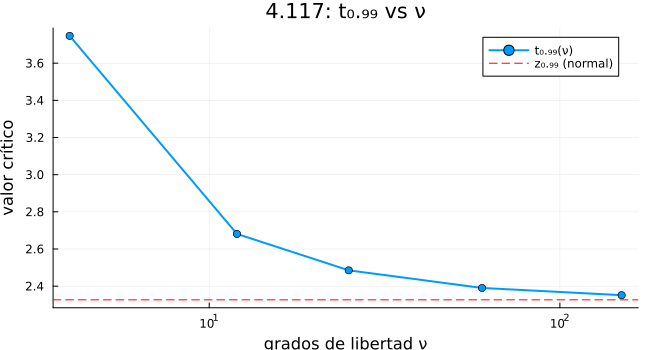

In [ ]:
νs = [4, 12, 25, 60, 150]
tvals = [quantile(TDist(ν), 0.99) for ν in νs]
for (ν, v) in zip(νs, tvals)
    println("ν = ", lpad(ν, 3), "   t₀.₉₉ = ", round(v, digits = 3))
end
println("límite normal z₀.₉₉ = ", round(quantile(Normal(), 0.99), digits = 3))

plot(νs, tvals, marker = :circle, lw = 2, label = "t₀.₉₉(ν)", xlabel = "grados de libertad ν",
     ylabel = "valor crítico", title = "4.117: t₀.₉₉ vs ν", xscale = :log10)
hline!([quantile(Normal(), 0.99)], ls = :dash, c = :red, label = "z₀.₉₉ (normal)")

---
## Ejercicio 4.118
**Enunciado.** Hallar los valores de $t_1$ de la distribución t de Student que satisfacen cada condición: (a) el área entre $-t_1$ y $t_1$ es 0.90 y $\nu=25$, (b) el área a la izquierda de $-t_1$ es 0.025 y $\nu=20$, (c) el área combinada a la derecha de $t_1$ y a la izquierda de $-t_1$ es 0.01 y $\nu=5$, (d) el área a la derecha de $t_1$ es 0.55 y $\nu=16$.

**Procedimiento.**

**(a)** Área central $0.90\Rightarrow$ cada cola $0.05\Rightarrow$ izquierda de $t_1$ vale $0.95$: $t_{0.95}(25)=\mathbf{1.71}$.

**(b)** Área izquierda de $-t_1$ es $0.025$; por simetría el área a la derecha de $t_1$ es $0.025$, así que izquierda de $t_1$ es $0.975$: $t_{0.975}(20)=\mathbf{2.09}$.

**(c)** Colas combinadas $0.01\Rightarrow$ cada una $0.005\Rightarrow$ $t_{0.995}(5)=\mathbf{4.03}$.

**(d)** Área a la derecha de $t_1$ es $0.55>0.5$, entonces $t_1$ está a la izquierda de 0. El área izquierda es $0.45$ y por simetría $t_{0.45}=-t_{0.55}$. Con $t_{0.55}(16)=0.128$:
$$t_1=\mathbf{-0.128}.$$

(a) t₁ = 1.708
(b) t₁ = 2.086
(c) t₁ = 4.032
(d) t₁ = -0.128


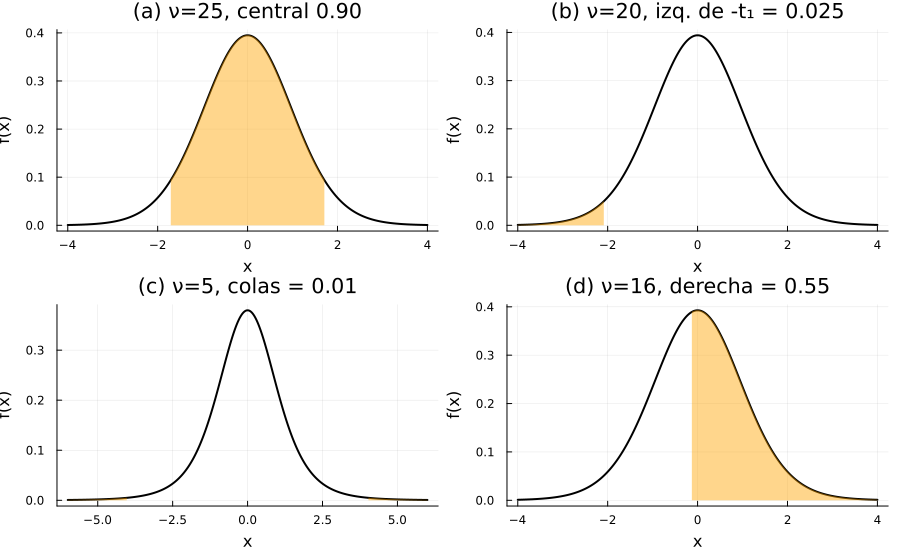

In [ ]:
t_a = quantile(TDist(25), 0.95)
t_b = quantile(TDist(20), 0.975)
t_c = quantile(TDist(5),  0.995)
t_d = quantile(TDist(16), 0.45)      # área derecha 0.55 ⇒ área izquierda 0.45
for (i, v) in zip("abcd", [t_a, t_b, t_c, t_d])
    println("($i) t₁ = ", round(v, digits = 3))
end

pa = sombra!(curva(TDist(25), lo = -4, hi = 4, titulo = "(a) ν=25, central 0.90"), TDist(25), -t_a, t_a, lo = -4, hi = 4)
pb = sombra!(curva(TDist(20), lo = -4, hi = 4, titulo = "(b) ν=20, izq. de -t₁ = 0.025"), TDist(20), -5, -t_b, lo = -4, hi = 4)
pc = curva(TDist(5), lo = -6, hi = 6, titulo = "(c) ν=5, colas = 0.01")
sombra!(pc, TDist(5), t_c, 7, lo = -6, hi = 6); sombra!(pc, TDist(5), -7, -t_c, lo = -6, hi = 6)
pd = sombra!(curva(TDist(16), lo = -4, hi = 4, titulo = "(d) ν=16, derecha = 0.55"), TDist(16), t_d, 5, lo = -4, hi = 4)
plot(pa, pb, pc, pd, layout = (2, 2), size = (900, 550))

---
## Ejercicio 4.120
**Enunciado.** Evaluar cada uno de los siguientes valores: (a) $F_{0.95,15,12}$; (b) $F_{0.99,120,60}$; (c) $F_{0.99,60,24}$; (d) $F_{0.01,30,12}$; (e) $F_{0.05,9,20}$; (f) $F_{0.01,8,8}$.

**Procedimiento.** $F_{p,\nu_1,\nu_2}$ es el valor con área $p$ a la izquierda en la distribución $F$ con $\nu_1$ grados de libertad en el numerador y $\nu_2$ en el denominador.

Los percentiles altos ($0.95$ y $0.99$) se leen directamente en las tablas del apéndice:

**(a)** $F_{0.95,15,12}=\mathbf{2.62}$  **(b)** $F_{0.99,120,60}=\mathbf{1.73}$  **(c)** $F_{0.99,60,24}=\mathbf{2.40}$

Los percentiles bajos ($0.01$ y $0.05$) no están en las tablas y se obtienen con la relación de reciprocidad
$$F_{1-p,\,\nu_1,\,\nu_2}=\frac{1}{F_{p,\,\nu_2,\,\nu_1}}\quad(\text{se intercambian los grados de libertad}).$$

**(d)** $F_{0.01,30,12}=\dfrac{1}{F_{0.99,12,30}}=\dfrac{1}{2.84}=\mathbf{0.352}$

**(e)** $F_{0.05,9,20}=\dfrac{1}{F_{0.95,20,9}}=\dfrac{1}{2.94}=\mathbf{0.340}$

**(f)** $F_{0.01,8,8}=\dfrac{1}{F_{0.99,8,8}}=\dfrac{1}{6.03}=\mathbf{0.166}$

(a) 2.617
(b) 1.726
(c) 2.403
(d) 0.352
(e) 0.341
(f) 0.166

Reciprocidad:
(d) 1/F₀.₉₉,₁₂,₃₀ = 0.352   F₀.₉₉,₁₂,₃₀ = 2.84
(e) 1/F₀.₉₅,₂₀,₉  = 0.341   F₀.₉₅,₂₀,₉  = 2.94
(f) 1/F₀.₉₉,₈,₈   = 0.166   F₀.₉₉,₈,₈   = 6.03


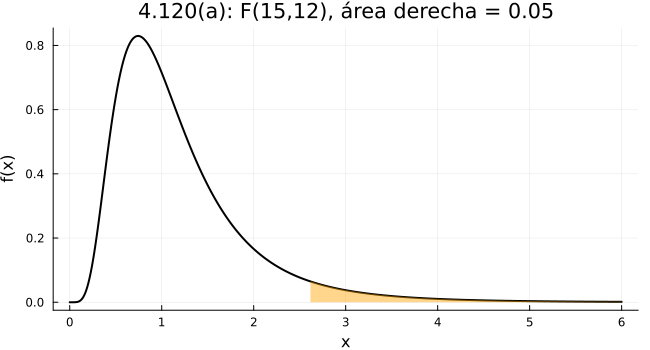

In [ ]:
Fq(p, ν1, ν2) = quantile(FDist(ν1, ν2), p)

vals = [Fq(0.95, 15, 12), Fq(0.99, 120, 60), Fq(0.99, 60, 24),
        Fq(0.01, 30, 12), Fq(0.05, 9, 20),   Fq(0.01, 8, 8)]
for (i, v) in zip("abcdef", vals)
    println("($i) ", round(v, digits = 3))
end

# Verificación de la relación de reciprocidad  F(1-p, ν1, ν2) = 1 / F(p, ν2, ν1)
println("\nReciprocidad:")
println("(d) 1/F₀.₉₉,₁₂,₃₀ = ", round(1 / Fq(0.99, 12, 30), digits = 3), "   F₀.₉₉,₁₂,₃₀ = ", round(Fq(0.99, 12, 30), digits = 2))
println("(e) 1/F₀.₉₅,₂₀,₉  = ", round(1 / Fq(0.95, 20, 9),  digits = 3), "   F₀.₉₅,₂₀,₉  = ", round(Fq(0.95, 20, 9), digits = 2))
println("(f) 1/F₀.₉₉,₈,₈   = ", round(1 / Fq(0.99, 8, 8),   digits = 3), "   F₀.₉₉,₈,₈   = ", round(Fq(0.99, 8, 8), digits = 2))

Fd = FDist(15, 12)
sombra!(curva(Fd, lo = 0.0, hi = 6.0, titulo = "4.120(a): F(15,12), área derecha = 0.05"), Fd, vals[1], 6.0, lo = 0.0, hi = 6.0)